# ITS awareness and adoption readiness among Ghanaian youth

Analysis code for the revised manuscript.

1. Data and coding
2. Structural paths and sociodemographic effects (Tables III and IV, Section IV.C.1)
3. PLS re-estimation of the structural model
4. Multi-group analysis (Table V)
5. Testing the willingness-familiarity paradox (Table VI, Section IV.F)
6. Respondent profiles (Figures 11-14)

Input: the raw survey export, read by column position. Set `INPUT` below; if that path does not
exist the notebook falls back to `data/ITS_Survey_Raw.xlsx`.

## 1. Data and coding

In [1]:
import os
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

INPUT = Path(r"F:\网页下载(包含大论文数据)\大论文\参考文献\ITS Survey(1-494) (2).xlsx")
FALLBACK = Path(os.environ.get("ITS_SURVEY", "data/ITS_Survey_Raw.xlsx"))
RAW_SURVEY = INPUT if INPUT.exists() else FALLBACK
if not RAW_SURVEY.exists():
    raise FileNotFoundError(f"survey file not found at {INPUT} or {FALLBACK}")

OUTPUT_DIR = Path("outputs")
FIGURE_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
print(f"reading {RAW_SURVEY}")

RANDOM_STATE = 42
N_BOOTSTRAP = 5000
N_BOOTSTRAP_CONTROLLED = 2000
N_PERMUTATIONS = 5000

BLOCKS = {
    "FAM": ["Familiarity"],
    "USE": ["Apps_Use_Freq"],
    "ATT": ["Improve_ITS", "Learn_More"],
    "BI": ["Would_Use_ITS"],
}
PATHS = {"FAM": ["USE"], "ATT": ["FAM", "USE"], "BI": ["FAM", "ATT", "USE"]}
PATH_ORDER = [("FAM", "USE"), ("ATT", "FAM"), ("ATT", "USE"),
              ("BI", "ATT"), ("BI", "USE"), ("BI", "FAM")]
DEMOGRAPHICS = ["Age", "Female", "Income", "Education", "Live", "GrewUp"]

d:\anaconda\D_anaconda3\lib\site-packages\statsmodels\tools\_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


reading F:\网页下载(包含大论文数据)\大论文\参考文献\ITS Survey(1-494) (2).xlsx


In [2]:
# The raw export has no stable header text, so columns are addressed by position.
RAW_COLUMNS = {
    "Familiarity": 7, "Technologies": 8, "Apps_Use_Freq": 9, "Challenges": 10,
    "Improve_ITS": 11, "Q1": 12, "Q2": 13, "Q3": 14, "Q4": 15, "Q5": 16, "Q6": 17,
    "Gov_Invest": 18, "Would_Use_ITS": 20, "Learn_More": 23, "GrewUp": 24, "Live": 25,
    "Age": 26, "Gender": 27, "Income": 28, "Education": 30,
}

# Improve_ITS collapses "Not Sure" and "It depends" onto the same midpoint; this coding
# reproduces the published path coefficients to four decimal places. Section 5 uses a
# four-level variant that treats "It depends" as a conditional endorsement.
CODEBOOK = {
    "Familiarity": {
        "Not at all familiar": 1,
        "Have heard the term but don't know what it means exactly": 2,
        "Have some understanding of it": 3,
        "Very familiar": 4,
    },
    "Apps_Use_Freq": {
        "Never": 1,
        "Rarely (couple of times a year or less)": 2,
        "Occasionally (couple of times per month or more)": 3,
        "Yes, frequently (few times per week or more)": 4,
    },
    "Would_Use_ITS": {"No": 1, "Maybe": 2, "Yes": 3},
    "Learn_More": {"No": 1, "Maybe": 2, "Yes": 3},
    "Improve_ITS": {"No": 1, "Not Sure": 2, "It depends": 2, "Yes": 3},
    "Age": {"18-24": 1, "25-34": 2, "35-44": 3, "45+": 4, "Prefer not to say": np.nan},
    "Gender": {"Male": 0, "Female": 1, "Non-binary": np.nan, "Prefer not to say": np.nan},
    "Income": {
        "No Income": 0, "Less than GHS 1,000": 1,
        "GHS 1,000 \u2013 3,000": 2, "GHS 1,000 - 3,000": 2,
        "GHS 3,000 \u2013 6,000": 3, "GHS 3,000 - 6,000": 3,
        "GHS 6,000 \u2013 10,000": 4, "GHS 6,000 - 10,000": 4,
        "More than GHS 10,000": 5, "Prefer not to say": np.nan,
    },
    "Place": {"Village": 1, "Town": 2, "City": 3, "Prefer not to say": np.nan},
    "Education": {
        "Primary School": 1, "High School": 2, "Nursing Training": 2, "Teacher Training": 2,
        "University (Undergraduate)": 3,
        "University (undergraduate) and acquired skills (Graphic designer)": 3,
        "Currently at the University doing my degree": 3,
        "University (Graduate)": 4, "Masters": 4, "Doctorate": 5,
        "Prefer not to say": np.nan,
    },
}

IMPROVE_FOUR_LEVEL = {"No": 1, "Not Sure": 2, "It depends": 3, "Yes": 4}
BENEFIT_SCALE = {
    "Not Beneficial at all": 1, "Slightly Beneficial": 2, "Moderately Beneficial": 3,
    "Very Beneficial": 4, "Extremely Beneficial": 5,
}
GOV_INVEST = {
    "No, there are more important priorities": 1, "Not sure": 2,
    "Yes, but only moderately": 3, "Yes, a lot more": 4,
}
CHALLENGES = {
    "Traffic congestion": "CH_congestion", "Poor road conditions": "CH_roads",
    "Road safety issues": "CH_safety", "High transportation costs": "CH_cost",
    "Poor public transportation": "CH_transit",
    "Lack of pedestrian and cycling infrastructure": "CH_nmt", "Air pollution": "CH_air",
}
TECHNOLOGY_CATEGORIES = {
    "consumer": [
        "Advanced transportation management systems (e.g. Uber, Bolt, etc.)",
        "Advanced traveler information systems (e.g. Google Maps, Apple Maps, etc.)",
    ],
    "transit": [
        "Advanced public transportation systems (e.g. Bus/train arrival times, shuttle systems, "
        "fare payment planning, etc.)",
        "Business vehicle management (e.g. Hubtel Delivery Driver assist)",
    ],
    "infrastructure": [
        "Advanced urban transportation systems (e.g. Adaptive traffic signal control, smart parking "
        "systems, Changeable message signs, etc.)",
        "Advanced vehicle control systems (e.g. Cruise Control, Adaptive Cruise Control, Automatic "
        "Emergency Braking, etc.)",
    ],
}
BENEFIT_ITEMS = {
    "Q1": ("smart signals", "infrastructure"),
    "Q2": ("transit apps", "consumer-facing"),
    "Q3": ("tolling", "infrastructure"),
    "Q4": ("enforcement cameras", "enforcement"),
    "Q5": ("GPS fleet management", "enforcement"),
    "Q6": ("self-driving / connected vehicles", "infrastructure"),
}

In [3]:
def normalise(value):
    if isinstance(value, str):
        return " ".join(value.replace("\xa0", " ").split()).strip()
    return value


def load_raw(path=RAW_SURVEY):
    """Read the raw export and drop rows without the two key items.

    Trailing and non-breaking spaces occur in several columns; without
    normalisation the affected values map to NaN silently.
    """
    raw = pd.read_excel(path)
    raw = raw.apply(lambda col: col.map(normalise))
    raw.columns = [normalise(c) for c in raw.columns]
    keep = [raw.columns[RAW_COLUMNS["Familiarity"]], raw.columns[RAW_COLUMNS["Would_Use_ITS"]]]
    return raw.dropna(subset=keep).reset_index(drop=True)


def column(raw, name):
    return raw.columns[RAW_COLUMNS[name]]


def code_indicators(raw):
    names = ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More", "Would_Use_ITS"]
    return pd.DataFrame({n: raw[column(raw, n)].map(CODEBOOK[n]) for n in names})


def code_demographics(raw):
    return pd.DataFrame({
        "Age": raw[column(raw, "Age")].map(CODEBOOK["Age"]),
        "Female": raw[column(raw, "Gender")].map(CODEBOOK["Gender"]),
        "Income": raw[column(raw, "Income")].map(CODEBOOK["Income"]),
        "Education": raw[column(raw, "Education")].map(CODEBOOK["Education"]),
        "Live": raw[column(raw, "Live")].map(CODEBOOK["Place"]),
        "GrewUp": raw[column(raw, "GrewUp")].map(CODEBOOK["Place"]),
    })


def composites(indicators):
    return pd.DataFrame({lv: indicators[items].mean(axis=1) for lv, items in BLOCKS.items()})


def build_cluster_frame(raw):
    """Numeric frame for the cluster figures, on the same codebook as the model."""
    frame = pd.concat([code_indicators(raw), code_demographics(raw)], axis=1)
    frame["Urban"] = (frame["Live"] == 3).astype(float).where(frame["Live"].notna())
    frame["UseYes"] = (frame["Would_Use_ITS"] == 3).astype(float).where(
        frame["Would_Use_ITS"].notna())
    return frame


raw = load_raw()
indicators = code_indicators(raw)
demographics = code_demographics(raw)
scores = composites(indicators)
cluster_frame = build_cluster_frame(raw)
print(f"respondents: {len(raw)}")
print(f"complete cases on the five indicators: {len(indicators.dropna())}")
indicators.describe().round(3)

respondents: 480
complete cases on the five indicators: 476


,Familiarity,Apps_Use_Freq,Improve_ITS,Learn_More,Would_Use_ITS
count,480.000,476.000,480.000,480.000,480.000
mean,2.044,2.987,2.617,2.815,2.842
std,0.974,0.882,0.516,0.458,0.448
min,1.000,1.000,1.000,1.000,1.000
25%,1.000,2.000,2.000,3.000,3.000
50%,2.000,3.000,3.000,3.000,3.000
75%,3.000,4.000,3.000,3.000,3.000
max,4.000,4.000,3.000,3.000,3.000


### 1a. Coverage check

Values reported as `UNMAPPED` are not in the codebook and become missing.

In [4]:
def coverage(name, mapping):
    values = raw[column(raw, name)].dropna().unique()
    unmapped = [v for v in values if v not in mapping]
    print(f"{name:<14} {'OK' if not unmapped else f'UNMAPPED -> {unmapped}'}")


for name in ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More", "Would_Use_ITS"]:
    coverage(name, CODEBOOK[name])
for name, key in [("Age", "Age"), ("Gender", "Gender"), ("Income", "Income"),
                  ("Live", "Place"), ("GrewUp", "Place"), ("Education", "Education")]:
    coverage(name, CODEBOOK[key])
for item in BENEFIT_ITEMS:
    coverage(item, BENEFIT_SCALE)
coverage("Gov_Invest", GOV_INVEST)

Familiarity    OK
Apps_Use_Freq  OK
Improve_ITS    OK
Learn_More     OK
Would_Use_ITS  OK
Age            OK
Gender         OK
Income         OK
Live           OK
GrewUp         OK
Education      OK
Q1             OK
Q2             OK
Q3             OK
Q4             OK
Q5             OK
Q6             OK
Gov_Invest     OK


## 2. Structural paths and sociodemographic effects

Tables III and IV are estimated on unweighted composite scores. Listwise deletion for Table IV runs
over the three outcomes and the demographics only, so its sample is slightly larger than for the
controlled structural model.

In [5]:
def structural_paths(data, controls=None):
    rows, r2 = [], {}
    for target, sources in PATHS.items():
        predictors = sources + (controls if controls else [])
        model = sm.OLS(data[target], sm.add_constant(data[predictors]), missing="drop").fit()
        scale = data[predictors + [target]].std()
        r2[target] = model.rsquared
        for source in sources:
            rows.append({
                "path": f"{source} -> {target}",
                "b": model.params[source],
                "beta": model.params[source] * scale[source] / scale[target],
                "se": model.bse[source],
                "p": model.pvalues[source],
                "n": int(model.nobs),
            })
    return pd.DataFrame(rows).set_index("path"), r2


base_paths, base_r2 = structural_paths(scores.dropna())
print("Table III, without controls")
print(base_paths.round(4).to_string())
print("R-squared: " + ", ".join(f"{k} = {v:.3f}" for k, v in base_r2.items()))

Table III, without controls
                 b    beta      se       p    n
path                                           
USE -> FAM  0.1116  0.1010  0.0505  0.0276  476
FAM -> ATT  0.0674  0.1728  0.0177  0.0002  476
USE -> ATT -0.0216 -0.0501  0.0196  0.2712  476
FAM -> BI   0.0045  0.0098  0.0207  0.8270  476
ATT -> BI   0.3203  0.2711  0.0529  0.0000  476
USE -> BI  -0.0445 -0.0875  0.0226  0.0491  476
R-squared: FAM = 0.010, ATT = 0.031, BI = 0.084


In [6]:
with_controls = pd.concat([scores, demographics], axis=1).dropna()
controlled_paths, controlled_r2 = structural_paths(with_controls, controls=DEMOGRAPHICS)
print("Table III, with sociodemographic controls")
print(controlled_paths.round(4).to_string())
print("R-squared: " + ", ".join(f"{k} = {v:.3f}" for k, v in controlled_r2.items()))

table3 = base_paths[["b", "beta", "p", "n"]].join(
    controlled_paths[["b", "p", "n"]], rsuffix="_controlled")
table3.round(4).to_csv(OUTPUT_DIR / "table3_structural_paths.csv")
table3.round(4)

Table III, with sociodemographic controls
                 b    beta      se       p    n
path                                           
USE -> FAM  0.0921  0.0824  0.0580  0.1133  406
FAM -> ATT  0.0551  0.1443  0.0189  0.0037  406
USE -> ATT  0.0182  0.0426  0.0219  0.4076  406
FAM -> BI  -0.0106 -0.0236  0.0222  0.6327  406
ATT -> BI   0.2300  0.1948  0.0584  0.0001  406
USE -> BI  -0.0406 -0.0805  0.0255  0.1128  406
R-squared: FAM = 0.042, ATT = 0.069, BI = 0.100


,b,beta,p,n,b_controlled,p_controlled,n_controlled
path,,,,,,,
USE -> FAM,0.1116,0.1010,0.0276,476,0.0921,0.1133,406
FAM -> ATT,0.0674,0.1728,0.0002,476,0.0551,0.0037,406
USE -> ATT,-0.0216,-0.0501,0.2712,476,0.0182,0.4076,406
FAM -> BI,0.0045,0.0098,0.8270,476,-0.0106,0.6327,406
ATT -> BI,0.3203,0.2711,0.0000,476,0.2300,0.0001,406
USE -> BI,-0.0445,-0.0875,0.0491,476,-0.0406,0.1128,406


### 2a. Measurement model (Section IV.C.1)

In [7]:
def cronbach_alpha(items):
    k = items.shape[1]
    return k / (k - 1) * (1 - items.var(ddof=1).sum() / items.sum(axis=1).var(ddof=1))


def measurement_statistics(indicators, scores):
    rows = []
    for lv, items in BLOCKS.items():
        loadings = np.array([np.corrcoef(indicators[i], scores[lv])[0, 1] for i in items])
        cr = loadings.sum() ** 2 / (loadings.sum() ** 2 + (1 - loadings ** 2).sum())
        ave = (loadings ** 2).mean()
        for item, loading in zip(items, loadings):
            rows.append({"construct": lv, "indicator": item, "loading": round(loading, 3),
                         "CR": round(cr, 3), "AVE": round(ave, 3), "k": len(items)})
    return pd.DataFrame(rows)


complete = indicators.dropna()
measurement = measurement_statistics(complete, composites(complete))
measurement.to_csv(OUTPUT_DIR / "table_measurement_model.csv", index=False)
print(measurement.to_string(index=False))

attitude = complete[["Improve_ITS", "Learn_More"]]
print(f"\nATT inter-item correlation r = {attitude.corr().iloc[0, 1]:.3f}, "
      f"Cronbach alpha = {cronbach_alpha(attitude):.3f}")

construct     indicator  loading    CR   AVE  k
      FAM   Familiarity    1.000 1.000 1.000  1
      USE Apps_Use_Freq    1.000 1.000 1.000  1
      ATT   Improve_ITS    0.808 0.759 0.611  2
      ATT    Learn_More    0.755 0.759 0.611  2
       BI Would_Use_ITS    1.000 1.000 1.000  1

ATT inter-item correlation r = 0.223, Cronbach alpha = 0.364


### 2b. Table IV — direct effects of sociodemographic characteristics

In [8]:
def sociodemographic_models(scores, demographics):
    """Table IV. Classical and HC3 p-values are both reported.

    The published table gives classical p-values; the robust column shows which
    of them survive a heteroskedasticity-consistent covariance.
    """
    frame = pd.concat([scores[["FAM", "ATT", "BI"]], demographics], axis=1).dropna()
    coefficients, fit = {}, {}
    for target in ["FAM", "ATT", "BI"]:
        model = sm.OLS(frame[target], sm.add_constant(frame[DEMOGRAPHICS])).fit()
        robust = model.get_robustcov_results(cov_type="HC3")
        scale = frame[DEMOGRAPHICS + [target]].std()
        for position, variable in enumerate(DEMOGRAPHICS, start=1):
            entry = coefficients.setdefault(variable, {})
            entry[f"{target}_b"] = round(model.params[variable], 3)
            entry[f"{target}_beta"] = round(
                model.params[variable] * scale[variable] / scale[target], 3)
            entry[f"{target}_p"] = round(model.pvalues[variable], 3)
            entry[f"{target}_p_HC3"] = round(robust.pvalues[position], 3)
        fit[target] = {"R2": round(model.rsquared, 3),
                       "model_p": round(model.f_pvalue, 4),
                       "model_p_HC3": round(float(np.squeeze(robust.f_pvalue)), 4),
                       "n": int(model.nobs)}
    return pd.DataFrame(coefficients).T, pd.DataFrame(fit).T


table4, table4_fit = sociodemographic_models(scores, demographics)
table4.to_csv(OUTPUT_DIR / "table4_sociodemographic_effects.csv")
print(table4.to_string())
print()
print(table4_fit.to_string())

           FAM_b  FAM_beta  FAM_p  FAM_p_HC3  ATT_b  ATT_beta  ATT_p  ATT_p_HC3   BI_b  BI_beta   BI_p  BI_p_HC3
Age       -0.109    -0.097  0.187      0.236 -0.028    -0.066  0.365      0.500 -0.058   -0.114  0.114     0.153
Female    -0.147    -0.075  0.130      0.129 -0.061    -0.081  0.101      0.113 -0.075   -0.085  0.084     0.112
Income     0.015     0.023  0.770      0.805 -0.046    -0.188  0.016      0.098 -0.034   -0.119  0.126     0.152
Education  0.182     0.103  0.068      0.074  0.080     0.119  0.034      0.075  0.152    0.191  0.001     0.009
Live       0.198     0.123  0.023      0.030  0.039     0.063  0.241      0.294  0.027    0.037  0.484     0.513
GrewUp     0.042     0.033  0.536      0.543 -0.013    -0.026  0.625      0.661  0.054    0.096  0.071     0.140

        R2  model_p  model_p_HC3      n
FAM  0.036   0.0199       0.0129  410.0
ATT  0.048   0.0029       0.0608  410.0
BI   0.058   0.0005       0.1371  410.0


## 3. PLS re-estimation

Partial least squares, Mode A measurement with the path weighting scheme. Three of the four
constructs are single-indicator, so their composite is the standardised indicator itself.

In [9]:
def zscore(values):
    values = np.asarray(values, dtype=float)
    sd = values.std(ddof=1)
    return values - values.mean() if sd == 0 else (values - values.mean()) / sd


def pls_sem(data, blocks, paths, max_iter=300, tol=1e-9, scheme="path"):
    lvs = list(blocks)
    X = {lv: np.column_stack([zscore(data[i]) for i in blocks[lv]]) for lv in lvs}

    adjacency = {lv: set() for lv in lvs}
    for target, sources in paths.items():
        for source in sources:
            adjacency[target].add(source)
            adjacency[source].add(target)

    weights = {lv: np.ones(X[lv].shape[1]) / np.sqrt(X[lv].shape[1]) for lv in lvs}
    Y = {lv: zscore(X[lv] @ weights[lv]) for lv in lvs}
    delta = np.inf

    for iteration in range(max_iter):
        inner = {}
        for lv in lvs:
            neighbours = sorted(adjacency[lv])
            if not neighbours:
                inner[lv] = Y[lv]
                continue
            if scheme == "path":
                predictors = paths.get(lv, [])
                if predictors:
                    design = np.column_stack([Y[p] for p in predictors])
                    coef = np.linalg.lstsq(design, Y[lv], rcond=None)[0]
                proxy = np.zeros(len(data))
                for neighbour in neighbours:
                    if neighbour in predictors:
                        proxy += coef[predictors.index(neighbour)] * Y[neighbour]
                    else:
                        proxy += np.corrcoef(Y[lv], Y[neighbour])[0, 1] * Y[neighbour]
            else:
                proxy = sum(np.sign(np.corrcoef(Y[lv], Y[n])[0, 1]) * Y[n] for n in neighbours)
            inner[lv] = zscore(proxy)

        new_weights = {}
        for lv in lvs:
            w = np.array([np.corrcoef(X[lv][:, j], inner[lv])[0, 1] for j in range(X[lv].shape[1])])
            norm = np.linalg.norm(w)
            new_weights[lv] = w / norm if norm > 0 else w
        new_Y = {lv: zscore(X[lv] @ new_weights[lv]) for lv in lvs}

        # A composite is identified only up to sign; anchor it to its first indicator.
        for lv in lvs:
            if np.corrcoef(new_Y[lv], X[lv][:, 0])[0, 1] < 0:
                new_Y[lv], new_weights[lv] = -new_Y[lv], -new_weights[lv]

        delta = max(np.abs(new_weights[lv] - weights[lv]).max() for lv in lvs)
        weights, Y = new_weights, new_Y
        if delta < tol:
            break

    coefficients, r2 = {}, {}
    for target, sources in paths.items():
        design = np.column_stack([Y[s] for s in sources])
        coef, *_ = np.linalg.lstsq(design, Y[target], rcond=None)
        coefficients[target] = dict(zip(sources, coef))
        residual = Y[target] - design @ coef
        r2[target] = 1 - residual.var(ddof=0) / Y[target].var(ddof=0)

    loadings, cr, ave = {}, {}, {}
    for lv in lvs:
        lam = np.array([np.corrcoef(X[lv][:, j], Y[lv])[0, 1] for j in range(X[lv].shape[1])])
        loadings[lv] = dict(zip(blocks[lv], lam))
        ave[lv] = float((lam ** 2).mean())
        cr[lv] = float(lam.sum() ** 2 / (lam.sum() ** 2 + (1 - lam ** 2).sum()))

    return {"weights": {lv: dict(zip(blocks[lv], weights[lv])) for lv in lvs},
            "scores": pd.DataFrame(Y, index=data.index), "paths": coefficients, "r2": r2,
            "loadings": loadings, "CR": cr, "AVE": ave,
            "n_iter": iteration + 1, "converged": delta < tol}


def flatten(fit):
    return {f"{s} -> {t}": b for t, sources in fit["paths"].items() for s, b in sources.items()}

In [10]:
D = indicators.dropna().reset_index(drop=True)
fit = pls_sem(D, BLOCKS, PATHS)
print(f"converged: {fit['converged']} after {fit['n_iter']} iterations\n")

print("Outer weights")
for lv, w in fit["weights"].items():
    print("  " + lv + ": " + ", ".join(f"{k} = {v:+.4f}" for k, v in w.items()))
print("\nStructural paths (standardised)")
for path, beta in flatten(fit).items():
    print(f"  {path}: {beta:+.4f}")
print("\nR-squared")
for lv, value in fit["r2"].items():
    print(f"  {lv}: {value:.4f}")

converged: True after 5 iterations

Outer weights
  FAM: Familiarity = +1.0000
  USE: Apps_Use_Freq = +1.0000
  ATT: Improve_ITS = +0.6175, Learn_More = +0.7866
  BI: Would_Use_ITS = +1.0000

Structural paths (standardised)
  USE -> FAM: +0.1010
  FAM -> ATT: +0.1795
  USE -> ATT: -0.0509
  FAM -> BI: +0.0075
  ATT -> BI: +0.2739
  USE -> BI: -0.0871

R-squared
  FAM: 0.0102
  ATT: 0.0330
  BI: 0.0848


### 3a. Bootstrap inference

Each resample is re-estimated in full and sign-aligned to the base solution.

In [11]:
def pls_bootstrap(data, blocks, paths, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE, **kwargs):
    rng = np.random.default_rng(seed)
    base = pls_sem(data, blocks, paths, **kwargs)
    keys = [(t, s) for t, sources in paths.items() for s in sources]
    draws = {k: [] for k in keys}

    for _ in range(n_boot):
        idx = rng.integers(0, len(data), len(data))
        try:
            resample = pls_sem(data.iloc[idx].reset_index(drop=True), blocks, paths, **kwargs)
        except Exception:
            continue
        flip = {}
        for lv in blocks:
            first_base = list(base["loadings"][lv].values())[0]
            first_new = list(resample["loadings"][lv].values())[0]
            flip[lv] = -1.0 if first_base * first_new < 0 else 1.0
        for target, source in keys:
            draws[(target, source)].append(
                resample["paths"][target][source] * flip[target] * flip[source])

    rows = []
    for target, source in keys:
        draw = np.array(draws[(target, source)])
        estimate = base["paths"][target][source]
        se = draw.std(ddof=1)
        low, high = np.percentile(draw, [2.5, 97.5])
        p = 2 * min((draw <= 0).mean(), (draw >= 0).mean())
        rows.append({"path": f"{source} -> {target}", "beta": estimate, "SE": se,
                     "CI_low": low, "CI_high": high,
                     "t": estimate / se if se > 0 else np.nan,
                     "p": max(p, 1 / (len(draw) + 1)), "n_boot": len(draw)})
    return base, pd.DataFrame(rows)


base, boot = pls_bootstrap(D, BLOCKS, PATHS)
boot["sig"] = pd.cut(boot["p"], [0, .001, .01, .05, 1], labels=["***", "**", "*", "n.s."])
boot = boot[["path", "beta", "SE", "CI_low", "CI_high", "t", "p", "sig"]].round(4)
boot.to_csv(OUTPUT_DIR / "pls_paths_bootstrap.csv", index=False)
boot

,path,beta,SE,CI_low,CI_high,t,p,sig
0,USE -> FAM,0.1010,0.0462,0.0096,0.1915,2.1854,0.0316,*
1,FAM -> ATT,0.1795,0.0388,0.1010,0.2523,4.6288,0.0002,***
2,USE -> ATT,-0.0509,0.0466,-0.1407,0.0401,-1.0926,0.2760,n.s.
3,FAM -> BI,0.0075,0.0436,-0.0812,0.0907,0.1720,0.8452,n.s.
4,ATT -> BI,0.2739,0.0570,0.1672,0.3900,4.8095,0.0002,***
5,USE -> BI,-0.0871,0.0444,-0.1694,0.0042,-1.9605,0.0628,n.s.


### 3b. PLS solution against unweighted composite scores

In [12]:
comparison = pd.DataFrame({
    "composite score (b)": base_paths["b"].round(4),
    "composite score (beta)": base_paths["beta"].round(4),
    "PLS-SEM (Mode A)": pd.Series(flatten(fit)).round(4),
})
comparison["difference"] = (
    comparison["PLS-SEM (Mode A)"] - comparison["composite score (beta)"]).round(4)
comparison.to_csv(OUTPUT_DIR / "pls_vs_composite.csv")
print(comparison.to_string())
print(f"\nlargest absolute difference: {comparison['difference'].abs().max():.4f}")

att_composite = zscore(D[["Improve_ITS", "Learn_More"]].mean(axis=1))
print("correlation between the two ATT composites: "
      f"{np.corrcoef(att_composite, fit['scores']['ATT'])[0, 1]:.5f}")

            composite score (b)  composite score (beta)  PLS-SEM (Mode A)  difference
USE -> FAM               0.1116                  0.1010            0.1010      0.0000
FAM -> ATT               0.0674                  0.1728            0.1795      0.0067
USE -> ATT              -0.0216                 -0.0501           -0.0509     -0.0008
FAM -> BI                0.0045                  0.0098            0.0075     -0.0023
ATT -> BI                0.3203                  0.2711            0.2739      0.0028
USE -> BI               -0.0445                 -0.0875           -0.0871      0.0004

largest absolute difference: 0.0067
correlation between the two ATT composites: 0.99044


### 3d. Is the attitude composite driven by one indicator?

In [13]:
for single in ["Improve_ITS", "Learn_More"]:
    single_fit = pls_sem(D, {**BLOCKS, "ATT": [single]}, PATHS)
    print(f'ATT measured by {single:<14} -> ATT -> BI = {single_fit["paths"]["BI"]["ATT"]:+.4f}, '
          f'FAM -> ATT = {single_fit["paths"]["ATT"]["FAM"]:+.4f}')
print(f'\nboth indicators -> ATT -> BI = {fit["paths"]["BI"]["ATT"]:+.4f}')

ATT measured by Improve_ITS    -> ATT -> BI = +0.1949, FAM -> ATT = +0.1039
ATT measured by Learn_More     -> ATT -> BI = +0.2269, FAM -> ATT = +0.1702

both indicators -> ATT -> BI = +0.2739


### 3e. External validation against `plspm`

Composites are identified only up to sign; compare magnitudes and relative signs. Optional cell:
install with `pip install plspm` or skip.

In [14]:
try:
    import plspm.config as pc
    from plspm.plspm import Plspm
    from plspm.scheme import Scheme
    from plspm.mode import Mode

    P = pd.DataFrame({"FAM_1": D.Familiarity, "USE_1": D.Apps_Use_Freq,
                      "ATT_1": D.Improve_ITS, "ATT_2": D.Learn_More,
                      "BI_1": D.Would_Use_ITS})
    structure = pc.Structure()
    structure.add_path(["USE"], ["FAM"])
    structure.add_path(["FAM", "USE"], ["ATT"])
    structure.add_path(["FAM", "ATT", "USE"], ["BI"])
    cfg = pc.Config(structure.path(), scaled=True)
    for lv in ["FAM", "USE", "BI", "ATT"]:
        cfg.add_lv_with_columns_named(lv, Mode.A, P, lv + "_")

    package = Plspm(P, cfg, Scheme.PATH)
    print("plspm package")
    print(package.inner_model()[["estimate", "std error", "t", "p>|t|"]].round(4).to_string())
    print("\nthis notebook")
    for path, beta in flatten(fit).items():
        print(f"  {path}: {beta:+.4f}")
except ImportError:
    print("plspm not installed - skipping external validation.")
except Exception as error:
    print(f"plspm check failed ({type(error).__name__}); this does not affect the analysis above.")
    print("Older plspm releases are incompatible with recent pandas versions.")

plspm not installed - skipping external validation.


### 3c. PLS model with sociodemographic controls

Each demographic characteristic enters as a single-indicator construct.

In [15]:
full = pd.concat([indicators, demographics], axis=1).dropna().reset_index(drop=True)
print(f"n with controls = {len(full)} ({len(D) - len(full)} lost to listwise deletion)")

blocks_c = {**BLOCKS, **{v: [v] for v in DEMOGRAPHICS}}
paths_c = {target: sources + DEMOGRAPHICS for target, sources in PATHS.items()}
fit_c = pls_sem(full, blocks_c, paths_c)

core = pd.DataFrame({
    "without controls": pd.Series(flatten(fit)),
    "with controls": pd.Series({f"{s} -> {t}": fit_c["paths"][t][s]
                                for t, sources in PATHS.items() for s in sources}),
}).round(4)
core["change"] = (core["with controls"] - core["without controls"]).round(4)
print(core.to_string())

demographic_paths = pd.DataFrame(
    {t: {v: round(fit_c["paths"][t][v], 4) for v in DEMOGRAPHICS} for t in ["FAM", "ATT", "BI"]})
demographic_paths.to_csv(OUTPUT_DIR / "pls_demographic_paths.csv")
print()
print(demographic_paths.to_string())

n with controls = 406 (70 lost to listwise deletion)
            without controls  with controls  change
USE -> FAM            0.1010         0.0824 -0.0186
FAM -> ATT            0.1795         0.1486 -0.0309
USE -> ATT           -0.0509         0.0693  0.1202
FAM -> BI             0.0075        -0.0225 -0.0300
ATT -> BI             0.2739         0.1819 -0.0920
USE -> BI            -0.0871        -0.0848  0.0023

              FAM     ATT      BI
Age       -0.1006 -0.0451 -0.0992
Female    -0.0790 -0.0790 -0.0685
Income     0.0030 -0.2594 -0.0633
Education  0.1018  0.1101  0.1787
Live       0.1082  0.0216  0.0451
GrewUp     0.0334 -0.0335  0.1052


In [16]:
_, boot_c = pls_bootstrap(full, blocks_c, paths_c, n_boot=N_BOOTSTRAP_CONTROLLED)
boot_c["sig"] = pd.cut(boot_c["p"], [0, .001, .01, .05, 1], labels=["***", "**", "*", "n.s."])
boot_c.round(4).to_csv(OUTPUT_DIR / "pls_controlled_bootstrap.csv", index=False)
core_paths = [f"{s} -> {t}" for t, sources in PATHS.items() for s in sources]
print(boot_c[boot_c.path.isin(core_paths)][
    ["path", "beta", "SE", "CI_low", "CI_high", "p", "sig"]].round(4).to_string(index=False))
print("\nDemographic paths reaching p < 0.05")
rest = boot_c[~boot_c.path.isin(core_paths)]
print(rest[rest.p < 0.05][["path", "beta", "CI_low", "CI_high", "p"]].round(4).to_string(index=False))

      path    beta     SE  CI_low  CI_high     p  sig
USE -> FAM  0.0824 0.0512 -0.0179   0.1822 0.106 n.s.
FAM -> ATT  0.1486 0.0434  0.0614   0.2327 0.001  ***
USE -> ATT  0.0693 0.0592 -0.0560   0.1769 0.257 n.s.
 FAM -> BI -0.0225 0.0495 -0.1151   0.0750 0.679 n.s.
 ATT -> BI  0.1819 0.0632  0.0524   0.2996 0.011    *
 USE -> BI -0.0848 0.0525 -0.1845   0.0236 0.124 n.s.

Demographic paths reaching p < 0.05
           path    beta  CI_low  CI_high     p
  Income -> ATT -0.2594 -0.4709  -0.0044 0.049
Education -> BI  0.1787  0.0517   0.3035 0.002


## 4. Multi-group analysis (Table V)

Each path is estimated within each subgroup as the slope of the endogenous composite on the
predictor alone; differences are referred to a permutation distribution (5,000 permutations per
path).

Notes on the table: the coefficients are bivariate slopes, not the multiple-regression coefficients
of Table III. Listwise deletion runs per path over the two variables involved, so paths within a
panel can rest on slightly different samples; panel headings report subgroup sizes before that
deletion. The multiple-regression version is printed afterwards.

In [17]:
GROUPINGS = {
    "gender": ("Female", lambda s: s == 0, "male", "female"),
    "age": ("Age", lambda s: s == 1, "18-24", "25+"),
    "residence": ("Live", lambda s: s == 3, "city", "town/village"),
    "upbringing": ("GrewUp", lambda s: s == 3, "city", "town/village"),
}


def slope(y, x):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()


def bivariate_mga(frame, group, n_perm=N_PERMUTATIONS, seed=RANDOM_STATE):
    """One permutation test per path, each on the rows complete for that path.

    The generator is seeded once per grouping and consumed path by path in the
    order of PATH_ORDER, which is what makes the p-values reproducible.
    """
    rng = np.random.default_rng(seed)
    rows = []
    for target, source in PATH_ORDER:
        sub = frame[[target, source]].assign(g=group.values).dropna()
        g = sub["g"].values.astype(bool)
        y, x = sub[target].values, sub[source].values
        b1, b2 = slope(y[g], x[g]), slope(y[~g], x[~g])
        observed = abs(b1 - b2)
        extreme = 0
        for _ in range(n_perm):
            perm = rng.permutation(g)
            if abs(slope(y[perm], x[perm]) - slope(y[~perm], x[~perm])) >= observed:
                extreme += 1
        rows.append({"path": f"{source} -> {target}", "group1": round(b1, 4),
                     "group2": round(b2, 4), "diff": round(b1 - b2, 4),
                     "p_perm": round((extreme + 1) / (n_perm + 1), 4),
                     "n_path": len(sub)})
    return pd.DataFrame(rows)


def subgroup_paths(data):
    coefficients = {}
    for target, sources in PATHS.items():
        model = sm.OLS(data[target], sm.add_constant(data[sources]), missing="drop").fit()
        for source in sources:
            coefficients[(target, source)] = model.params[source]
    return coefficients


def multivariate_mga(data, group, n_perm=N_PERMUTATIONS, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    first, second = subgroup_paths(data[group]), subgroup_paths(data[~group])
    observed = {key: first[key] - second[key] for key in PATH_ORDER}
    extreme = {key: 0 for key in PATH_ORDER}
    labels = np.asarray(group)
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        a, b = subgroup_paths(data[shuffled]), subgroup_paths(data[~shuffled])
        for key in PATH_ORDER:
            if abs(a[key] - b[key]) >= abs(observed[key]):
                extreme[key] += 1
    return pd.DataFrame([{
        "path": f"{source} -> {target}",
        "group1": round(first[(target, source)], 4),
        "group2": round(second[(target, source)], 4),
        "diff": round(observed[(target, source)], 4),
        "p_perm": round((extreme[(target, source)] + 1) / (n_perm + 1), 4),
    } for target, source in PATH_ORDER])


table5, table5_multivariate, mga_sizes = [], [], {}
for label, (variable, rule, name1, name2) in GROUPINGS.items():
    frame = (pd.concat([indicators, demographics[[variable]]], axis=1)
             .dropna(subset=[variable]).reset_index(drop=True))
    group = rule(frame[variable])
    scores_g = composites(frame.drop(columns=variable))
    mga_sizes[label] = (int(group.sum()), int((~group).sum()))
    print(f"=== {label}: {name1} n = {group.sum()}, {name2} n = {(~group).sum()} "
          f"(group1 = {name1}) ===")
    result = bivariate_mga(scores_g, group)
    print(result.to_string(index=False))
    table5.append(result.assign(grouping=label))
    table5_multivariate.append(multivariate_mga(scores_g, group).assign(grouping=label))
    print()

pd.concat(table5).to_csv(OUTPUT_DIR / "table5_mga_all.csv", index=False)
pd.concat(table5_multivariate).to_csv(OUTPUT_DIR / "table5_mga_multivariate.csv", index=False)

print("For reference: the same comparison with each path taken from the multiple-regression")
print("equations of Table III rather than from bivariate slopes.")
print(pd.concat(table5_multivariate).to_string(index=False))

=== gender: male n = 242, female n = 230 (group1 = male) ===
      path  group1  group2    diff  p_perm  n_path
USE -> FAM  0.1949  0.0270  0.1679  0.1034     468
FAM -> ATT  0.0283  0.1054 -0.0771  0.0208     472
USE -> ATT  0.0019 -0.0274  0.0294  0.4759     468
 ATT -> BI  0.1537  0.4290 -0.2753  0.0618     472
 USE -> BI -0.0250 -0.0728  0.0478  0.3313     468
 FAM -> BI -0.0401  0.0957 -0.1357  0.0006     472

=== age: 18-24 n = 279, 25+ n = 190 (group1 = 18-24) ===
      path  group1  group2    diff  p_perm  n_path
USE -> FAM  0.1305  0.0714  0.0591  0.5661     465
FAM -> ATT  0.0485  0.0793 -0.0308  0.3715     469
USE -> ATT  0.0289 -0.0698  0.0986  0.0150     465
 ATT -> BI  0.1714  0.4580 -0.2866  0.0612     469
 USE -> BI  0.0013 -0.1057  0.1070  0.0322     465
 FAM -> BI -0.0158  0.0620 -0.0778  0.0738     469

=== residence: city n = 263, town/village n = 206 (group1 = city) ===
      path  group1  group2    diff  p_perm  n_path
USE -> FAM  0.0822  0.0677  0.0145  0.8888   

## 5. Testing the willingness-familiarity paradox (Table VI)

Three segments are formed by crossing familiarity with adoption intention and compared on three
mechanisms: transport-app use frequency (M1), number of transport problems endorsed (M2), and rated
benefit of consumer-facing ITS (M3).

Low familiarity is `FAM <= 2`; high willingness is a `Yes` on the adoption item, with `Maybe` not
counted as willing.

This section uses the four-level coding of `Improve_ITS`, which places "It depends" above
"Not Sure". It affects only the attitude composite used below, not the structural model.

In [18]:
LOW_FAMILIARITY_CUT = 2
NONE_OF_THE_ABOVE = "none of the above"
MECHANISMS = ["USE", "DISSAT", "BEN_CONSUMER"]
MECHANISMS_PANEL_C = MECHANISMS + ["Q6"]
FULL_SPECIFICATION = ["USE", "DISSAT", "DISSAT_TRANSIT", "BEN_CONSUMER", "BEN_ENFORCE",
                      "BEN_INFRA", "AGE", "FEMALE", "INCOME", "URBAN", "EDU"]
GROUPS = ["HW-LF", "HW-HF", "LowWill"]


def split_multiselect(value):
    if pd.isna(value):
        return []
    return [token.strip() for token in str(value).split(";") if token.strip()]


def matches(tokens, options):
    lowered = {option.strip().lower() for option in options}
    return int(any(token.strip().lower() in lowered for token in tokens))


def encode_paradox(raw):
    d = pd.DataFrame(index=raw.index)
    d["FAM"] = raw[column(raw, "Familiarity")].map(CODEBOOK["Familiarity"])
    d["WILL"] = raw[column(raw, "Would_Use_ITS")].map(CODEBOOK["Would_Use_ITS"])
    d["USE"] = raw[column(raw, "Apps_Use_Freq")].map(CODEBOOK["Apps_Use_Freq"])

    d["IMPROVE"] = raw[column(raw, "Improve_ITS")].map(IMPROVE_FOUR_LEVEL)
    d["IMPROVE_YES"] = (raw[column(raw, "Improve_ITS")] == "Yes").astype(int)
    d["LEARN"] = raw[column(raw, "Learn_More")].map(CODEBOOK["Learn_More"])
    d["GOV"] = raw[column(raw, "Gov_Invest")].map(GOV_INVEST)
    d["ATT"] = ((d["IMPROVE"] - 1) / 3 + (d["LEARN"] - 1) / 2) / 2

    for item in BENEFIT_ITEMS:
        d[item] = raw[column(raw, item)].map(BENEFIT_SCALE)
    d["BEN_CONSUMER"] = d[["Q2"]].mean(axis=1)
    d["BEN_ENFORCE"] = d[["Q4", "Q5"]].mean(axis=1)
    d["BEN_INFRA"] = d[["Q1", "Q3", "Q6"]].mean(axis=1)
    d["BEN_MEAN"] = d[list(BENEFIT_ITEMS)].mean(axis=1)

    challenges = raw[column(raw, "Challenges")].apply(split_multiselect)
    for option, short in CHALLENGES.items():
        d[short] = challenges.apply(lambda t, o=option: matches(t, [o]))
    d["DISSAT"] = d[list(CHALLENGES.values())].sum(axis=1)
    d["DISSAT_NONE"] = challenges.apply(lambda t: matches(t, [NONE_OF_THE_ABOVE]))
    d["DISSAT_TRANSIT"] = d["CH_transit"]
    # A handful of respondents ticked "None of the above" alongside real options.
    # Their endorsements are kept: zeroing them would discard genuine answers.

    technologies = raw[column(raw, "Technologies")].apply(split_multiselect)
    for category, options in TECHNOLOGY_CATEGORIES.items():
        d[f"TECH_{category.upper()}"] = technologies.apply(lambda t, o=options: matches(t, o))
    d["TECH_NONE"] = technologies.apply(lambda t: matches(t, [NONE_OF_THE_ABOVE]))
    d["TECH_COUNT"] = technologies.apply(
        lambda tokens: sum(1 for t in tokens if t.lower() != NONE_OF_THE_ABOVE))
    d["TECH_ZERO"] = (d["TECH_COUNT"] == 0).astype(int)

    d["AGE"] = raw[column(raw, "Age")].map(CODEBOOK["Age"])
    d["FEMALE"] = raw[column(raw, "Gender")].map(CODEBOOK["Gender"])
    d["INCOME"] = raw[column(raw, "Income")].map(CODEBOOK["Income"])
    d["LIVE"] = raw[column(raw, "Live")].map(CODEBOOK["Place"])
    d["URBAN"] = (d["LIVE"] == 3).astype(float).where(d["LIVE"].notna())
    d["GREWUP"] = raw[column(raw, "GrewUp")].map(CODEBOOK["Place"])
    d["EDU"] = raw[column(raw, "Education")].map(CODEBOOK["Education"])

    d["LOWFAM"] = (d["FAM"] <= LOW_FAMILIARITY_CUT).astype(int)
    d["HIGHWILL"] = (d["WILL"] == 3).astype(int)
    d["GROUP"] = np.where(d["HIGHWILL"].eq(1) & d["LOWFAM"].eq(1), "HW-LF",
                          np.where(d["HIGHWILL"].eq(1), "HW-HF", "LowWill"))
    return d


d = encode_paradox(raw)
counts = d["GROUP"].value_counts()
print(counts.to_frame("n").assign(pct=(counts / len(d) * 100).round(1)).to_string())
print(f"\noverall willingness (Yes): {d['HIGHWILL'].mean() * 100:.1f}%")

           n   pct
HW-LF    290  60.4
HW-HF    130  27.1
LowWill   60  12.5

overall willingness (Yes): 87.5%


Willingness is ceiling-bound, so associations with it are attenuated. The analysis below uses group contrasts.

In [19]:
crosstab = pd.crosstab(d["FAM"], d["WILL"])
crosstab["all"] = crosstab.sum(axis=1)
crosstab["% willing"] = (crosstab[3] / crosstab["all"] * 100).round(1)
print("Familiarity x willingness")
print(crosstab.to_string())

Familiarity x willingness
WILL  1   2    3  all  % willing
FAM                             
1     6  20  145  171       84.8
2     5  13  145  163       89.0
3     3  10   87  100       87.0
4     2   1   43   46       93.5


### 5a. Panel A — segment profiles

In [20]:
def epsilon_squared(h, n, k):
    return (h - k + 1) / (n - k)


def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


PANEL_A_VARIABLES = [
    ("USE", "M1 app-use frequency"),
    ("DISSAT", "M2 transport problems endorsed"),
    ("BEN_CONSUMER", "M3 consumer-facing benefit"),
    ("BEN_ENFORCE", "enforcement benefit"),
    ("BEN_INFRA", "infrastructure benefit"),
    ("TECH_COUNT", "ITS technologies recognised"),
]

rows = []
for variable, mechanism in PANEL_A_VARIABLES:
    samples = [d.loc[d.GROUP == g, variable].dropna() for g in GROUPS]
    h, p = stats.kruskal(*samples)
    n = sum(len(s) for s in samples)
    rows.append({"variable": variable, "mechanism": mechanism, "test": "Kruskal-Wallis",
                 **{g: round(s.mean(), 3) for g, s in zip(GROUPS, samples)},
                 "stat": round(h, 3), "p": round(p, 4),
                 "effect": round(epsilon_squared(h, n, 3), 4), "effect_type": "epsilon^2"})

# The binary rows are summarised with the same epsilon-squared as the rest of the
# panel; Cramer's V is reported alongside rather than in its place.
for variable, mechanism in [("TECH_ZERO", "recognises no listed technology"),
                            ("TECH_NONE", "selected none of the above"),
                            ("DISSAT_TRANSIT", "M2 transit-specific"),
                            ("IMPROVE_YES", "believes ITS improves transport")]:
    samples = [d.loc[d.GROUP == g, variable].dropna() for g in GROUPS]
    h, p = stats.kruskal(*samples)
    n = sum(len(s) for s in samples)
    rows.append({"variable": variable, "mechanism": mechanism, "test": "Kruskal-Wallis",
                 **{g: round(s.mean(), 3) for g, s in zip(GROUPS, samples)},
                 "stat": round(h, 3), "p": round(p, 4),
                 "effect": round(epsilon_squared(h, n, 3), 4), "effect_type": "epsilon^2",
                 "cramers_v": round(cramers_v(pd.crosstab(d["GROUP"], d[variable])), 4)})

panel_a = pd.DataFrame(rows)
panel_a.to_csv(OUTPUT_DIR / "table6_panelA_segment_profiles.csv", index=False)
panel_a

,variable,mechanism,test,HW-LF,HW-HF,LowWill,stat,p,effect,effect_type,cramers_v
0,USE,M1 app-use frequency,Kruskal-Wallis,2.916,3.092,3.100,4.590,0.1008,0.0055,epsilon^2,NaN
1,DISSAT,M2 transport problems endorsed,Kruskal-Wallis,3.231,3.769,3.350,5.996,0.0499,0.0084,epsilon^2,NaN
2,BEN_CONSUMER,M3 consumer-facing benefit,Kruskal-Wallis,3.800,4.062,3.017,37.301,0.0000,0.0740,epsilon^2,NaN
3,BEN_ENFORCE,enforcement benefit,Kruskal-Wallis,4.040,4.262,3.592,25.159,0.0000,0.0486,epsilon^2,NaN
4,BEN_INFRA,infrastructure benefit,Kruskal-Wallis,3.566,3.659,2.911,34.844,0.0000,0.0689,epsilon^2,NaN
5,TECH_COUNT,ITS technologies recognised,Kruskal-Wallis,2.197,3.054,2.067,24.901,0.0000,0.0480,epsilon^2,NaN
6,TECH_ZERO,recognises no listed technology,Kruskal-Wallis,0.110,0.008,0.067,13.372,0.0012,0.0238,epsilon^2,0.1671
7,TECH_NONE,selected none of the above,Kruskal-Wallis,0.128,0.008,0.100,15.521,0.0004,0.0283,epsilon^2,0.1800
8,DISSAT_TRANSIT,M2 transit-specific,Kruskal-Wallis,0.452,0.515,0.467,1.462,0.4815,-0.0011,epsilon^2,0.0552
9,IMPROVE_YES,believes ITS improves transport,Kruskal-Wallis,0.662,0.700,0.333,26.645,0.0000,0.0517,epsilon^2,0.2359


In [21]:
# HW-LF against informed adopters, the contrast the comment concerns
for variable in ["USE", "DISSAT", "BEN_CONSUMER", "TECH_COUNT", "AGE", "INCOME"]:
    a = d.loc[d.GROUP == "HW-LF", variable].dropna()
    b = d.loc[d.GROUP == "HW-HF", variable].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    print(f"{variable:<14} HW-LF = {a.mean():.3f}  HW-HF = {b.mean():.3f}  "
          f"U = {u:>9.0f}  p = {p:.4f}  r_rb = {1 - 2 * u / (len(a) * len(b)):+.3f}")

USE            HW-LF = 2.916  HW-HF = 3.092  U =     16715  p = 0.0800  r_rb = +0.101
DISSAT         HW-LF = 3.231  HW-HF = 3.769  U =     16078  p = 0.0141  r_rb = +0.147
BEN_CONSUMER   HW-LF = 3.800  HW-HF = 4.062  U =     16182  p = 0.0128  r_rb = +0.142
TECH_COUNT     HW-LF = 2.197  HW-HF = 3.054  U =     13598  p = 0.0000  r_rb = +0.279
AGE            HW-LF = 1.582  HW-HF = 1.661  U =     17252  p = 0.3869  r_rb = +0.047
INCOME         HW-LF = 1.057  HW-HF = 1.282  U =     14408  p = 0.2516  r_rb = +0.067


### 5b. Panels B and C

Events per variable are printed for each model. The full specification, adding the remaining benefit
measures and five demographic controls, follows as a robustness check.

In [22]:
def multinomial(d, predictors):
    frame = d[["GROUP"] + predictors].dropna()
    y = frame["GROUP"].map({"HW-HF": 0, "HW-LF": 1, "LowWill": 2})
    model = sm.MNLogit(y, sm.add_constant(frame[predictors].astype(float))).fit(disp=False)

    tables = {}
    for equation, label in enumerate(["HW-LF vs HW-HF", "LowWill vs HW-HF"]):
        params, se = model.params.iloc[:, equation], model.bse.iloc[:, equation]
        tables[label] = pd.DataFrame({
            "coef": params.round(3), "OR": np.exp(params).round(3),
            "CI_low": np.exp(params - 1.96 * se).round(3),
            "CI_high": np.exp(params + 1.96 * se).round(3),
            "p": model.pvalues.iloc[:, equation].round(4)})
    smallest = int(y.value_counts().min())
    fit = {"n": int(model.nobs), "pseudo_R2": round(model.prsquared, 4),
           "LR_p": round(model.llr_pvalue, 4), "smallest_cell": smallest,
           "events_per_variable": round(smallest / len(predictors), 1)}
    return tables, fit


def within_low_familiarity(d, predictors):
    frame = d[d["LOWFAM"] == 1][["HIGHWILL"] + predictors].dropna()
    model = smf.logit("HIGHWILL ~ " + " + ".join(predictors), data=frame).fit(disp=False)
    table = pd.DataFrame({
        "coef": model.params.round(3), "OR": np.exp(model.params).round(3),
        "CI_low": np.exp(model.params - 1.96 * model.bse).round(3),
        "CI_high": np.exp(model.params + 1.96 * model.bse).round(3),
        "p": model.pvalues.round(4)})
    events = int(min(frame["HIGHWILL"].sum(), (1 - frame["HIGHWILL"]).sum()))
    fit = {"n": int(model.nobs), "not_willing": int((1 - frame["HIGHWILL"]).sum()),
           "pseudo_R2": round(model.prsquared, 4),
           "events_per_variable": round(events / len(predictors), 1)}
    return table, fit


panel_b, fit_b = multinomial(d, MECHANISMS)
print(f"Panel B, reported specification: {fit_b}\n")
for label, table in panel_b.items():
    print(label)
    print(table.to_string())
    print()
    table.to_csv(OUTPUT_DIR / f"table6_panelB_{label.split()[0].lower()}.csv")

Panel B, reported specification: {'n': 476, 'pseudo_R2': 0.0531, 'LR_p': 0.0, 'smallest_cell': 60, 'events_per_variable': 20.0}

HW-LF vs HW-HF
               coef      OR  CI_low  CI_high       p
const         2.733  15.378   4.575   51.694  0.0000
USE          -0.207   0.813   0.635    1.041  0.1002
DISSAT       -0.086   0.918   0.831    1.013  0.0872
BEN_CONSUMER -0.259   0.771   0.610    0.975  0.0298

LowWill vs HW-HF
               coef      OR  CI_low  CI_high       p
const         2.569  13.052   2.515   67.744  0.0022
USE          -0.017   0.983   0.673    1.437  0.9304
DISSAT       -0.023   0.977   0.840    1.137  0.7677
BEN_CONSUMER -0.892   0.410   0.302    0.556  0.0000



In [23]:
panel_c, fit_c = within_low_familiarity(d, MECHANISMS_PANEL_C)
panel_c.to_csv(OUTPUT_DIR / "table6_panelC_within_low_familiarity.csv")
print(f"Panel C, reported specification: {fit_c}\n")
print(panel_c.to_string())

Panel C, reported specification: {'n': 330, 'not_willing': 44, 'pseudo_R2': 0.1159, 'events_per_variable': 11.0}

               coef     OR  CI_low  CI_high       p
Intercept    -1.039  0.354   0.068    1.836  0.2163
USE           0.064  1.066   0.725    1.567  0.7467
DISSAT       -0.010  0.990   0.842    1.163  0.8993
BEN_CONSUMER  0.397  1.487   1.100    2.011  0.0100
Q6            0.512  1.668   1.242    2.240  0.0007


In [24]:
robust_b, fit_robust_b = multinomial(d, FULL_SPECIFICATION)
robust_b["HW-LF vs HW-HF"].to_csv(OUTPUT_DIR / "robustness_mnlogit_full.csv")
print(f"Robustness, full specification: {fit_robust_b}\n")
print(robust_b["HW-LF vs HW-HF"].to_string())

robust_c, fit_robust_c = within_low_familiarity(d, FULL_SPECIFICATION)
robust_c.to_csv(OUTPUT_DIR / "robustness_logit_full.csv")
print(f"\nRobustness, within low familiarity: {fit_robust_c}\n")
print(robust_c.to_string())

Robustness, full specification: {'n': 409, 'pseudo_R2': 0.0812, 'LR_p': 0.0, 'smallest_cell': 47, 'events_per_variable': 4.3}

                 coef      OR  CI_low  CI_high       p
const           3.751  42.570   4.620  392.278  0.0009
USE            -0.200   0.818   0.614    1.091  0.1718
DISSAT         -0.150   0.860   0.733    1.011  0.0670
DISSAT_TRANSIT  0.493   1.637   0.832    3.222  0.1536
BEN_CONSUMER   -0.344   0.709   0.511    0.983  0.0390
BEN_ENFORCE    -0.109   0.897   0.619    1.299  0.5658
BEN_INFRA       0.134   1.144   0.793    1.649  0.4717
AGE             0.185   1.203   0.797    1.817  0.3785
FEMALE         -0.066   0.936   0.587    1.495  0.7833
INCOME         -0.008   0.992   0.774    1.272  0.9504
URBAN          -0.489   0.613   0.372    1.010  0.0547
EDU            -0.209   0.812   0.487    1.351  0.4223

Robustness, within low familiarity: {'n': 285, 'not_willing': 34, 'pseudo_R2': 0.1382, 'events_per_variable': 3.1}

                 coef     OR  CI_low  CI_

### 5c. ITS categories

Recognition shares are computed over selections rather than respondents.

In [25]:
categories = pd.DataFrame([{
    "item": f"{item} {description}", "category": category,
    "mean": round(d[item].mean(), 3), "sd": round(d[item].std(), 3),
    "mean_HW-LF": round(d.loc[d.GROUP == "HW-LF", item].mean(), 3),
} for item, (description, category) in BENEFIT_ITEMS.items()])
categories.to_csv(OUTPUT_DIR / "table_its_category_profile.csv", index=False)
print(categories.to_string(index=False))

technologies = raw[column(raw, "Technologies")].apply(split_multiselect)
selection_counts = {}
for category, options in TECHNOLOGY_CATEGORIES.items():
    lowered = {option.strip().lower() for option in options}
    selection_counts[category] = sum(
        1 for tokens in technologies for t in tokens if t.strip().lower() in lowered)
# "None of the above" counts as a response, so it belongs in the denominator:
# the shares describe the composition of all answers, not of recognised items only.
total = sum(len(tokens) for tokens in technologies)
recognition_shares = (pd.Series(selection_counts) / total * 100).round(1)
print(f"\nRecognition responses by category ({total} selections)")
print(recognition_shares.to_string())

print("\nShare of respondents recognising at least one item in each category")
print(d.groupby("GROUP")[["TECH_CONSUMER", "TECH_TRANSIT", "TECH_INFRASTRUCTURE",
                          "TECH_ZERO"]].mean().round(3).to_string())

                                item        category  mean    sd  mean_HW-LF
                    Q1 smart signals  infrastructure 3.769 0.869       3.800
                     Q2 transit apps consumer-facing 3.773 1.046       3.800
                          Q3 tolling  infrastructure 3.627 1.136       3.679
              Q4 enforcement cameras     enforcement 4.083 0.991       4.076
             Q5 GPS fleet management     enforcement 4.004 0.956       4.003
Q6 self-driving / connected vehicles  infrastructure 3.131 1.295       3.217

Recognition responses by category (1202 selections)
consumer          54.4
transit           27.5
infrastructure    14.4

Share of respondents recognising at least one item in each category
         TECH_CONSUMER  TECH_TRANSIT  TECH_INFRASTRUCTURE  TECH_ZERO
GROUP                                                               
HW-HF            0.931         0.631                0.377      0.008
HW-LF            0.814         0.452                0.217      

In [26]:
# Per-challenge decomposition: is any specific grievance linked to attitude or willingness?
rows = []
for option, short in CHALLENGES.items():
    endorsed = d.loc[d[short] == 1, "ATT"].dropna()
    not_endorsed = d.loc[d[short] == 0, "ATT"].dropna()
    _, p_attitude = stats.mannwhitneyu(endorsed, not_endorsed, alternative="two-sided")
    _, p_willing, _, _ = stats.chi2_contingency(pd.crosstab(d[short], d["HIGHWILL"]))
    rows.append({"challenge": option, "n_endorsing": int(d[short].sum()),
                 "ATT_if_endorsed": round(endorsed.mean(), 3),
                 "ATT_if_not": round(not_endorsed.mean(), 3), "p_ATT": round(p_attitude, 4),
                 "willing_if_endorsed": round(d.loc[d[short] == 1, "HIGHWILL"].mean(), 3),
                 "willing_if_not": round(d.loc[d[short] == 0, "HIGHWILL"].mean(), 3),
                 "p_willing": round(p_willing, 4)})
challenge_table = pd.DataFrame(rows).sort_values("n_endorsing", ascending=False)
challenge_table.to_csv(OUTPUT_DIR / "table_challenge_decomposition.csv", index=False)
challenge_table

,challenge,n_endorsing,ATT_if_endorsed,ATT_if_not,p_ATT,willing_if_endorsed,willing_if_not,p_willing
1,Poor road conditions,325,0.886,0.875,0.6916,0.886,0.852,0.3563
0,Traffic congestion,269,0.859,0.912,0.0043,0.866,0.886,0.6021
2,Road safety issues,240,0.880,0.884,0.7046,0.875,0.875,1.0000
3,High transportation costs,227,0.886,0.879,0.7168,0.907,0.846,0.0574
4,Poor public transportation,226,0.876,0.888,0.2639,0.876,0.874,1.0000
5,Lack of pedestrian and cycling infrastructure,198,0.859,0.898,0.0162,0.854,0.890,0.2931
6,Air pollution,143,0.846,0.897,0.0098,0.860,0.881,0.6239


### 5d. Sensitivity to the segment definition

In [27]:
strict = np.where((d.WILL == 3) & (d.FAM == 1), "HW-LF",
                  np.where(d.WILL == 3, "HW-HF", "LowWill"))
strict_frame = d.assign(GROUP_STRICT=strict)
print("Low familiarity restricted to 'not at all familiar'")
print(strict_frame["GROUP_STRICT"].value_counts().to_string())
print()
print(strict_frame.groupby("GROUP_STRICT")[
    ["USE", "DISSAT", "BEN_CONSUMER", "BEN_ENFORCE", "BEN_INFRA"]].mean().round(3).to_string())
print(f"\nwillingness including 'Maybe': {(d.WILL >= 2).mean() * 100:.1f}%")

Low familiarity restricted to 'not at all familiar'
HW-HF      275
HW-LF      145
LowWill     60

                USE  DISSAT  BEN_CONSUMER  BEN_ENFORCE  BEN_INFRA
GROUP_STRICT                                                     
HW-HF         3.015   3.480         3.945        4.191      3.639
HW-LF         2.888   3.241         3.759        3.952      3.510
LowWill       3.100   3.350         3.017        3.592      2.911

willingness including 'Maybe': 96.7%


## 6. Respondent profiles (Figures 11-14)

K-means cluster indices are arbitrary, so group names are attached by the rank of a group's overall
profile. Each figure prints the group means alongside an automatically generated description.

Silhouette scores are printed for k = 2 to 5 before each figure.

Clustering variables come from `cluster_frame`, built in Section 1 from the same export and codebook
as the structural model.

In [28]:
AXIS_LABELS = {
    "Familiarity": "Familiarity with ITS",
    "Apps_Use_Freq": "Frequency of using\ntransport apps",
    "Improve_ITS": "Believes ITS improves\ntransport",
    "Learn_More": "Willing to learn\nmore about ITS",
    "Would_Use_ITS": "Willing to adopt ITS",
    "UseYes": "Willing to adopt ITS",
    "Income": "Monthly income",
    "Age": "Age",
    "Urban": "Lives in a city",
}
COLOURS = ["#4965b0", "#f36f43", "#4c9f70", "#a30543", "#7b5aa6"]
RUN_STABILITY = True


def label_for(name, inline=False):
    label = AXIS_LABELS.get(name, name.replace("_", " "))
    return label.replace("\n", " ") if inline else label


def fit_clusters(sub, k, random_state=RANDOM_STATE):
    X = StandardScaler().fit_transform(sub.values)
    return KMeans(n_clusters=k, random_state=random_state, n_init=10).fit_predict(X)


def silhouette_report(sub, ks=(2, 3, 4, 5)):
    X = StandardScaler().fit_transform(sub.values)
    scores = {}
    for k in ks:
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
        scores[k] = silhouette_score(X, labels)
        print(f"  k = {k}: silhouette = {scores[k]:.3f}")
    best = max(scores, key=scores.get)
    print(f"  best k = {best} (silhouette = {scores[best]:.3f})")
    if scores[best] < 0.25:
        print("  below 0.25: the partition describes gradients rather than separated segments")
    return best, scores


def cluster_stability(sub, k, n_boot=50):
    rng = np.random.default_rng(RANDOM_STATE)
    baseline = fit_clusters(sub, k)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(sub), len(sub))
        labels = fit_clusters(sub.iloc[idx], k)
        unique, first = np.unique(idx, return_index=True)
        values.append(adjusted_rand_score(baseline[unique], labels[first]))
    values = np.array(values)
    print(f"  bootstrap ARI: mean = {values.mean():.3f}, "
          f"5th-95th pct = [{np.percentile(values, 5):.3f}, {np.percentile(values, 95):.3f}]")
    return values


def profile(sub, labels):
    tmp = sub.copy()
    tmp["cluster"] = labels
    means = tmp.groupby("cluster").mean()
    normalised = (means - sub.min()) / (sub.max() - sub.min())
    counts = tmp["cluster"].value_counts().sort_index()
    return means, normalised, counts, (counts / counts.sum() * 100).round(1)


def describe_groups(normalised):
    order = normalised.mean(axis=1).sort_values(ascending=False).index.tolist()
    column_max, column_min = normalised.max(axis=0), normalised.min(axis=0)
    phrases = {}
    for cluster in order:
        row = normalised.loc[cluster]
        is_max = (row - column_max).abs() < 1e-9
        is_min = (row - column_min).abs() < 1e-9
        if is_max.all():
            phrases[cluster] = "highest on every dimension"
        elif is_min.all():
            phrases[cluster] = "lowest on every dimension"
        else:
            parts = []
            tops = [label_for(f, inline=True) for f in row[is_max].index][:2]
            bottoms = [label_for(f, inline=True) for f in row[is_min].index][:2]
            if tops:
                parts.append("highest on " + " and ".join(tops))
            if bottoms:
                parts.append("lowest on " + " and ".join(bottoms))
            phrases[cluster] = "; ".join(parts) if parts else "mid-range on all dimensions"
    return phrases, order


def legend_labels(normalised, counts, share, manual=None):
    """manual runs from the highest overall profile to the lowest."""
    phrases, order = describe_groups(normalised)
    labels = {}
    for rank, cluster in enumerate(order):
        name = manual[rank] if manual is not None and rank < len(manual) else phrases[cluster]
        labels[cluster] = f"{name} ({share[cluster]}% of respondents, N={counts[cluster]})"
    return labels, order


def radar_plot(features, labels, normalised, order, figname=None, wrap=52):
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    figure = plt.figure(figsize=(7.0, 7.8))
    ax = figure.add_axes([0.14, 0.33, 0.72, 0.61], polar=True)
    for i, cluster in enumerate(order):
        values = normalised.loc[cluster].tolist()
        values += values[:1]
        colour = COLOURS[i % len(COLOURS)]
        ax.plot(angles, values, linewidth=2.2, color=colour,
                label=textwrap.fill(labels[cluster], wrap))
        ax.fill(angles, values, alpha=0.14, color=colour)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([label_for(f) for f in features], fontsize=11)
    ax.tick_params(axis="x", pad=14)
    ax.set_ylim(0, 1)
    ax.set_rlabel_position(180.0 / len(features))
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=8, color="grey")
    ax.grid(alpha=0.5)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), frameon=False,
              fontsize=10, ncol=1, handlelength=1.8, labelspacing=0.8)
    if figname:
        figure.savefig(FIGURE_DIR / f"{figname}.png", dpi=300, bbox_inches="tight")
    plt.show()


def caption_helper(title, means, normalised, labels, order):
    phrases, _ = describe_groups(normalised)
    print(f"\n--- caption helper: {title} ---")
    print("Radar values are min-max normalised; the means below are on the original scale.\n")
    for cluster in order:
        stats_line = ", ".join(f"{label_for(c, inline=True)} = {means.loc[cluster, c]:.2f}"
                               for c in means.columns)
        print(f"* {labels[cluster]}")
        print(f"    data check: {phrases[cluster]}")
        print(f"    {stats_line}\n")


def make_figure(frame, features, k, manual, figname, title, choose_k=False):
    features = [f for f in features if f in frame.columns]
    sub = frame[features].dropna()
    print(f"=== {title}  (n = {len(sub)}) ===")
    print("Silhouette scores:")
    best_k, _ = silhouette_report(sub)
    if choose_k:
        k = best_k
        print(f"  using the best k = {k}")
    else:
        print(f"  k fixed at {k} for comparability with the manuscript")

    labels = fit_clusters(sub, k)
    if RUN_STABILITY:
        cluster_stability(sub, k)

    means, normalised, counts, share = profile(sub, labels)
    manual = manual if manual and len(manual) >= k else None
    named, order = legend_labels(normalised, counts, share, manual=manual)
    radar_plot(features, named, normalised, order, figname=figname)
    caption_helper(title, means, normalised, named, order)
    return {"labels": pd.Series(labels, index=sub.index), "means": means,
            "counts": counts, "share": share, "order": order}

=== Fig. 11 - behavioural and socio-demographic profiles  (n = 417) ===
Silhouette scores:
  k = 2: silhouette = 0.257
  k = 3: silhouette = 0.199
  k = 4: silhouette = 0.211
  k = 5: silhouette = 0.213
  best k = 2 (silhouette = 0.257)
  using the best k = 2
  bootstrap ARI: mean = 0.957, 5th-95th pct = [0.887, 1.000]


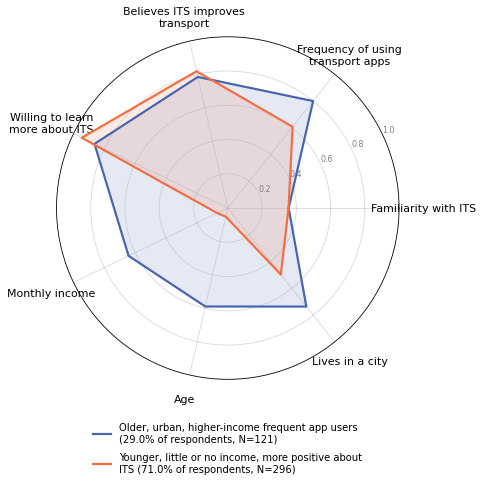


--- caption helper: Fig. 11 - behavioural and socio-demographic profiles ---
Radar values are min-max normalised; the means below are on the original scale.

* Older, urban, higher-income frequent app users (29.0% of respondents, N=121)
    data check: highest on Familiarity with ITS and Frequency of using transport apps; lowest on Believes ITS improves transport and Willing to learn more about ITS
    Familiarity with ITS = 2.07, Frequency of using transport apps = 3.40, Believes ITS improves transport = 2.57, Willing to learn more about ITS = 2.73, Monthly income = 3.21, Age = 2.77, Lives in a city = 0.74

* Younger, little or no income, more positive about ITS (71.0% of respondents, N=296)
    data check: highest on Believes ITS improves transport and Willing to learn more about ITS; lowest on Familiarity with ITS and Frequency of using transport apps
    Familiarity with ITS = 2.06, Frequency of using transport apps = 2.82, Believes ITS improves transport = 2.64, Willing to learn 

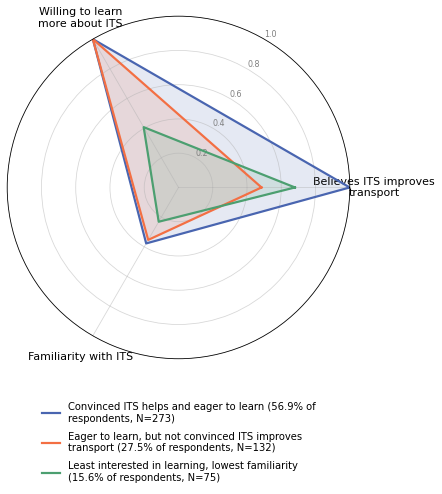


--- caption helper: Fig. 12 - attitudinal profiles ---
Radar values are min-max normalised; the means below are on the original scale.

* Convinced ITS helps and eager to learn (56.9% of respondents, N=273)
    data check: highest on every dimension
    Believes ITS improves transport = 3.00, Willing to learn more about ITS = 3.00, Familiarity with ITS = 2.13

* Eager to learn, but not convinced ITS improves transport (27.5% of respondents, N=132)
    data check: highest on Willing to learn more about ITS; lowest on Believes ITS improves transport
    Believes ITS improves transport = 1.97, Willing to learn more about ITS = 3.00, Familiarity with ITS = 2.06

* Least interested in learning, lowest familiarity (15.6% of respondents, N=75)
    data check: lowest on Willing to learn more about ITS and Familiarity with ITS
    Believes ITS improves transport = 2.36, Willing to learn more about ITS = 1.81, Familiarity with ITS = 1.69

=== Fig. 13 - technology-engagement profiles  (n = 476) 

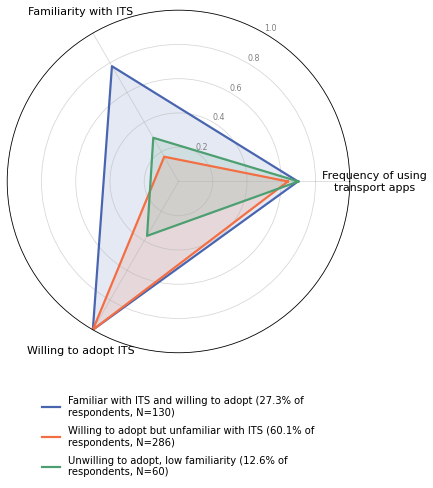


--- caption helper: Fig. 13 - technology-engagement profiles ---
Radar values are min-max normalised; the means below are on the original scale.

* Familiar with ITS and willing to adopt (27.3% of respondents, N=130)
    data check: highest on Familiarity with ITS and Willing to adopt ITS
    Frequency of using transport apps = 3.09, Familiarity with ITS = 3.33, Willing to adopt ITS = 3.00

* Willing to adopt but unfamiliar with ITS (60.1% of respondents, N=286)
    data check: highest on Willing to adopt ITS; lowest on Frequency of using transport apps and Familiarity with ITS
    Frequency of using transport apps = 2.92, Familiarity with ITS = 1.50, Willing to adopt ITS = 3.00

* Unwilling to adopt, low familiarity (12.6% of respondents, N=60)
    data check: highest on Frequency of using transport apps; lowest on Willing to adopt ITS
    Frequency of using transport apps = 3.10, Familiarity with ITS = 1.88, Willing to adopt ITS = 1.73

=== Fig. 14 - adoption-readiness profiles  (n 

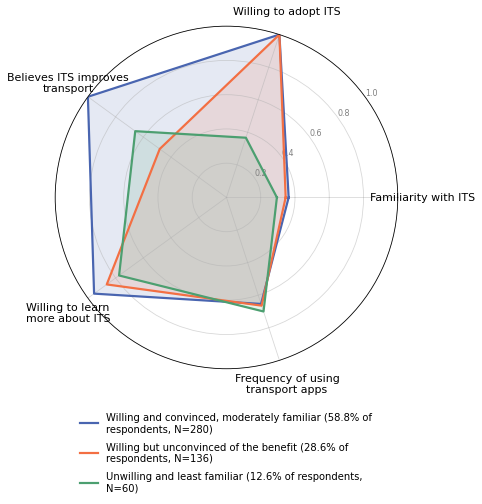


--- caption helper: Fig. 14 - adoption-readiness profiles ---
Radar values are min-max normalised; the means below are on the original scale.

* Willing and convinced, moderately familiar (58.8% of respondents, N=280)
    data check: highest on Familiarity with ITS and Willing to adopt ITS; lowest on Frequency of using transport apps
    Familiarity with ITS = 2.09, Willing to adopt ITS = 3.00, Believes ITS improves transport = 3.00, Willing to learn more about ITS = 2.91, Frequency of using transport apps = 2.96

* Willing but unconvinced of the benefit (28.6% of respondents, N=136)
    data check: highest on Willing to adopt ITS; lowest on Believes ITS improves transport
    Familiarity with ITS = 2.04, Willing to adopt ITS = 3.00, Believes ITS improves transport = 1.96, Willing to learn more about ITS = 2.73, Frequency of using transport apps = 2.99

* Unwilling and least familiar (12.6% of respondents, N=60)
    data check: highest on Frequency of using transport apps; lowest on F

In [29]:
FIGURES = {
    "fig11_segmentation": {
        "title": "Fig. 11 - behavioural and socio-demographic profiles",
        "features": ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More",
                     "Income", "Age", "Urban"],
        "k": 2, "choose_k": True,
        "labels": ["Older, urban, higher-income frequent app users",
                   "Younger, little or no income, more positive about ITS"],
    },
    "fig12_attitudes": {
        "title": "Fig. 12 - attitudinal profiles",
        "features": ["Improve_ITS", "Learn_More", "Familiarity"],
        "k": 3, "choose_k": False,
        "labels": ["Convinced ITS helps and eager to learn",
                   "Eager to learn, but not convinced ITS improves transport",
                   "Least interested in learning, lowest familiarity"],
    },
    "fig13_tech_engagement": {
        "title": "Fig. 13 - technology-engagement profiles",
        "features": ["Apps_Use_Freq", "Familiarity", "Would_Use_ITS"],
        "k": 3, "choose_k": False,
        "labels": ["Familiar with ITS and willing to adopt",
                   "Willing to adopt but unfamiliar with ITS",
                   "Unwilling to adopt, low familiarity"],
    },
    "fig14_adoption_readiness": {
        "title": "Fig. 14 - adoption-readiness profiles",
        "features": ["Familiarity", "Would_Use_ITS", "Improve_ITS", "Learn_More", "Apps_Use_Freq"],
        "k": 3, "choose_k": False,
        "labels": ["Willing and convinced, moderately familiar",
                   "Willing but unconvinced of the benefit",
                   "Unwilling and least familiar"],
    },
}

figures = {}
for figname, spec in FIGURES.items():
    figures[figname] = make_figure(cluster_frame, spec["features"], spec["k"], spec["labels"],
                                   figname, spec["title"], choose_k=spec["choose_k"])
    figures[figname]["means"].round(3).to_csv(OUTPUT_DIR / f"{figname}_means.csv")

In [30]:
# Figs. 13 and 14 are reported as sharing their low-willingness group.
def lowest_group(result):
    lowest = result["order"][-1]
    return set(result["labels"][result["labels"] == lowest].index)


a = lowest_group(figures["fig13_tech_engagement"])
b = lowest_group(figures["fig14_adoption_readiness"])
print(f"low-willingness group: Fig. 13 N = {len(a)}, Fig. 14 N = {len(b)}, shared = {len(a & b)}")

low-willingness group: Fig. 13 N = 60, Fig. 14 N = 60, shared = 60


In [31]:
def audit_multiselect(column_name, known):
    tokens = raw[column(raw, column_name)].apply(split_multiselect)
    counts = {}
    for row in tokens:
        for t in row:
            counts[t.strip()] = counts.get(t.strip(), 0) + 1
    known_lower = {k.strip().lower() for k in known} | {NONE_OF_THE_ABOVE}
    print(f"--- {column_name}: {len(counts)} distinct options, "
          f"{sum(counts.values())} selections ---")
    for token, n in sorted(counts.items(), key=lambda kv: -kv[1]):
        flag = "" if token.lower() in known_lower else "   <-- UNMATCHED"
        print(f"  {n:>4}  {token[:88]}{flag}")
    print()


audit_multiselect("Challenges", CHALLENGES)
audit_multiselect("Technologies",
                  [o for options in TECHNOLOGY_CATEGORIES.values() for o in options])

--- Challenges: 19 distinct options, 1649 selections ---
   325  Poor road conditions
   269  Traffic congestion
   240  Road safety issues
   227  High transportation costs
   226  Poor public transportation
   198  Lack of pedestrian and cycling infrastructure
   143  Air pollution
    10  None of the above
     1  Poor condition of public buses and taxis   <-- UNMATCHED
     1  Inexperience drivers   <-- UNMATCHED
     1  Knowledge of public transport routes   <-- UNMATCHED
     1  Police not addressing street children and drivers that violate the driving rules of the    <-- UNMATCHED
     1  Noise pollution   <-- UNMATCHED
     1  Poor road signals and inapproapriate traffic lights   <-- UNMATCHED
     1  * Bad weather conditions * Poor telecommunication coverage for Google map and Uber trans   <-- UNMATCHED
     1  Drivers over speeding   <-- UNMATCHED
     1  Overloading of passengers and drivers too are taking hard drugs   <-- UNMATCHED
     1  COST OF TIME   <-- UNMATCHED
     

### 7. Coding of "Prefer not to say"

In [32]:
TARGET_FIG11 = [128, 348]


def fig11_group_sizes(age_fill, income_fill, live_fill, improve_levels=3):
    frame = cluster_frame.copy()
    if improve_levels == 4:
        frame["Improve_ITS"] = raw[column(raw, "Improve_ITS")].map(IMPROVE_FOUR_LEVEL)
    frame["Age"] = frame["Age"].fillna(age_fill)
    frame["Income"] = frame["Income"].fillna(income_fill)
    live = demographics["Live"].fillna(live_fill)
    frame["Urban"] = (live == 3).astype(float).where(live.notna())
    features = ["Familiarity", "Apps_Use_Freq", "Improve_ITS", "Learn_More",
                "Income", "Age", "Urban"]
    sub = frame[features].dropna()
    if len(sub) < 2:
        return len(sub), []
    labels = fit_clusters(sub, 2)
    return len(sub), sorted(pd.Series(labels).value_counts().tolist(), reverse=True)


candidates = {
    "missing": np.nan,
    "zero": 0,
    "next": None,          # one above the top category
    "median": None,        # median of the observed values
}
grids = {}
for name, series in [("Age", demographics["Age"]), ("Income", demographics["Income"]),
                     ("Live", demographics["Live"])]:
    grids[name] = {"missing": np.nan, "zero": 0.0,
                   "next": float(series.max() + 1), "median": float(series.median())}

print(f"target group sizes: {TARGET_FIG11}\n")
results = []
for levels in (3, 4):
    for age_label, age_fill in grids["Age"].items():
        for income_label, income_fill in grids["Income"].items():
            for live_label, live_fill in grids["Live"].items():
                n, sizes = fig11_group_sizes(age_fill, income_fill, live_fill, levels)
                distance = sum(abs(a - b) for a, b in zip(sizes, TARGET_FIG11)) if sizes else 999
                results.append((distance, levels, age_label, income_label, live_label, n, sizes))

for distance, levels, age_label, income_label, live_label, n, sizes in sorted(results)[:12]:
    match = " <-- MATCH" if distance == 0 else f"  (off by {distance})"
    print(f"improve={levels}-level age={age_label:<8} income={income_label:<8} "
          f"live={live_label:<8} n={n:<4} sizes={sizes}{match}")
print(f"\n{sum(1 for r in results if r[0] == 0)} exact matches out of {len(results)} combinations")

target group sizes: [128, 348]

improve=3-level age=next     income=next     live=median   n=476  sizes=[303, 173]  (off by 350)
improve=3-level age=next     income=next     live=next     n=476  sizes=[303, 173]  (off by 350)
improve=3-level age=next     income=next     live=zero     n=476  sizes=[303, 173]  (off by 350)
improve=4-level age=next     income=next     live=median   n=476  sizes=[303, 173]  (off by 350)
improve=4-level age=next     income=next     live=next     n=476  sizes=[303, 173]  (off by 350)
improve=4-level age=next     income=next     live=zero     n=476  sizes=[303, 173]  (off by 350)
improve=3-level age=median   income=next     live=missing  n=465  sizes=[298, 167]  (off by 351)
improve=3-level age=next     income=next     live=missing  n=465  sizes=[298, 167]  (off by 351)
improve=3-level age=zero     income=next     live=missing  n=465  sizes=[298, 167]  (off by 351)
improve=4-level age=next     income=next     live=missing  n=465  sizes=[298, 167]  (off by 351

### 7c. Scaling used for the silhouette scores

In [33]:
from sklearn.preprocessing import MinMaxScaler

SCALINGS = {
    "raw": lambda X: X,
    "standardised": lambda X: StandardScaler().fit_transform(X),
    "min-max": lambda X: MinMaxScaler().fit_transform(X),
}

print(f"{'figure':<26}{'k':>3}" + "".join(f"{name:>16}" for name in SCALINGS))
for figname, spec in FIGURES.items():
    features = [f for f in spec["features"] if f in cluster_frame.columns]
    sub = cluster_frame[features].dropna()
    k = len(figures[figname]["counts"])
    line = f"{figname:<26}{k:>3}"
    for scale in SCALINGS.values():
        X = scale(sub.values)
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)
        line += f"{silhouette_score(X, labels):>16.3f}"
    print(line)
print("\nThe published range is 0.19-0.25.")

figure                      k             raw    standardised         min-max
fig11_segmentation          2           0.400           0.257           0.348
fig12_attitudes             3           0.482           0.499           0.485
fig13_tech_engagement       3           0.427           0.396           0.398
fig14_adoption_readiness    3           0.317           0.298           0.272

The published range is 0.19-0.25.
